# Cluster

##### K-Means: K-Means is a centroid-based clustering algorithm that partitions data into k clusters by minimizing the intra-cluster variance (distance to the center).
#####	Clusters are shaped like circles (spherical)
#####	Sensitive to outliers and initial centroids

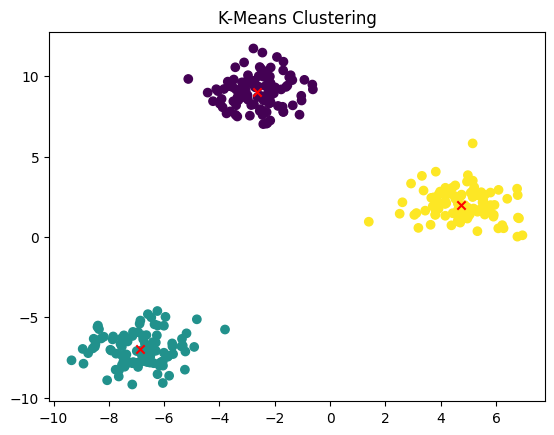

In [1]:
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

X, _ = make_blobs(n_samples=300, centers=3, random_state=42)

kmeans = KMeans(n_clusters=3)
y_kmeans = kmeans.fit_predict(X)

plt.scatter(X[:, 0], X[:, 1], c=y_kmeans, cmap='viridis')
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1], c='red', marker='x')
plt.title("K-Means Clustering")
plt.show()

##### DBSCAN groups together points that are closely packed (high density) and marks points in low-density regions as outliers.
###### Good for irregularly shaped clusters
######	No need to specify number of clusters
###### Can detect noise 

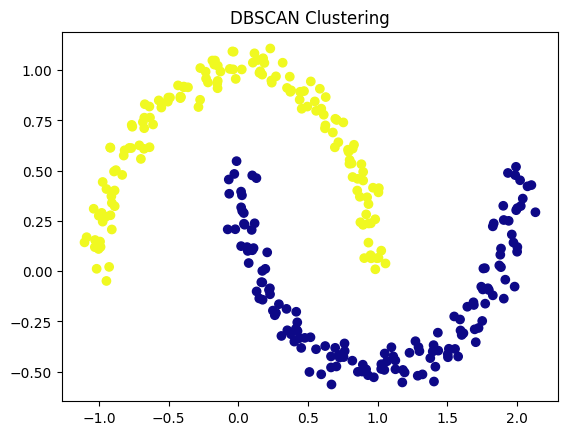

In [2]:
from sklearn.datasets import make_moons
from sklearn.cluster import DBSCAN

X, _ = make_moons(n_samples=300, noise=0.05, random_state=42)

dbscan = DBSCAN(eps=0.2, min_samples=5)
y_dbscan = dbscan.fit_predict(X)

plt.scatter(X[:, 0], X[:, 1], c=y_dbscan, cmap='plasma')
plt.title("DBSCAN Clustering")
plt.show()

##### Agglomerative clustering: A bottom-up hierarchical clustering technique that starts with each data point as its own cluster and merges the closest pairs until a stopping criterion is met.
##### No need to predefine number of clusters (if using dendrogram)
###### Results can be visualized using a dendrogram

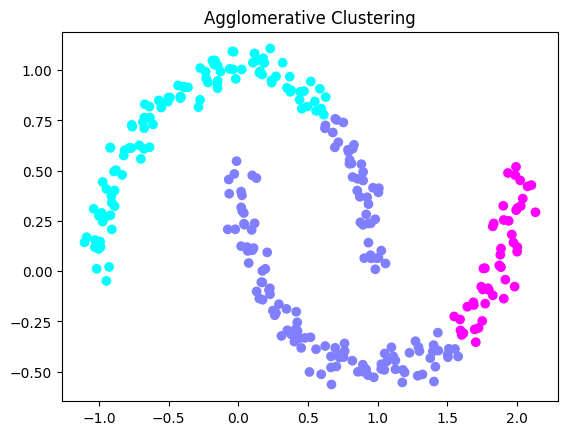

In [3]:
from sklearn.cluster import AgglomerativeClustering

agglo = AgglomerativeClustering(n_clusters=3)
y_agglo = agglo.fit_predict(X)

plt.scatter(X[:, 0], X[:, 1], c=y_agglo, cmap='cool')
plt.title("Agglomerative Clustering")
plt.show()

###### Gausian Mixture Model: GMM is a probabilistic model that assumes data is generated from a mixture of multiple Gaussian distributions. It uses soft clustering, where a point can belong to multiple clusters with different probabilities.
######	Each cluster is a Gaussian (ellipse-shaped)
######	Suitable for overlapping clusters
######	Outputs cluster probabilities per point

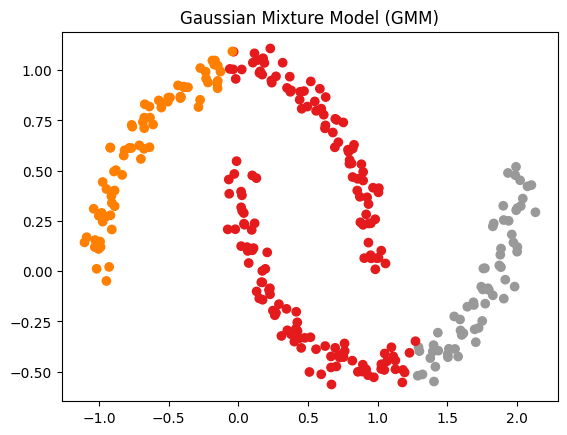

In [4]:
from sklearn.mixture import GaussianMixture

gmm = GaussianMixture(n_components=3)
gmm.fit(X)
y_gmm = gmm.predict(X)

plt.scatter(X[:, 0], X[:, 1], c=y_gmm, cmap='Set1')
plt.title("Gaussian Mixture Model (GMM)")
plt.show()

###### PCA is a dimensionality reduction technique that projects data into a lower-dimensional space by identifying directions (principal components) that maximize variance.
###### Eigenvectors → directions of principal components
######	Eigenvalues → variance explained by each component
######	Used for visualization and feature reduction

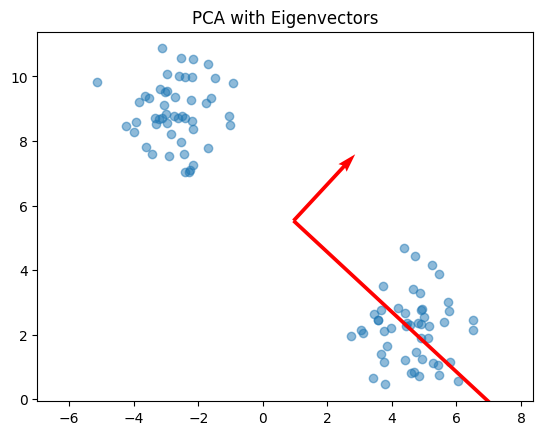

In [5]:
from sklearn.decomposition import PCA
import numpy as np

X, _ = make_blobs(n_samples=100, centers=2, n_features=2, random_state=42)

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

# Eigenvectors and Eigenvalues
eigenvectors = pca.components_
eigenvalues = pca.explained_variance_

# Plot original data
plt.scatter(X[:, 0], X[:, 1], alpha=0.5)
for length, vector in zip(eigenvalues, eigenvectors):
    v = vector * 3 * np.sqrt(length)
    plt.quiver(pca.mean_[0], pca.mean_[1], v[0], v[1], angles='xy', scale_units='xy', scale=1, color='r')
plt.title("PCA with Eigenvectors")
plt.axis('equal')
plt.show()